# Day 6 - Data Governance & Partition Freeze

## Objective

Establish data governance boundaries, define partition freeze rules, and quarantine test data against developmental leakage.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_6_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Governance Policy Formulation

Document immutable governance rules: zero in-place mutation, chronological partition isolation, and quarantine seals.

In [2]:
policies = [
    {"Rule_ID": "GOV_01", "Policy": "Raw Data Immutability", "Enforcement": "Read-Only Permissions; SHA-256 Digest Verification"},
    {"Rule_ID": "GOV_02", "Policy": "Chronological Partitioning", "Enforcement": "Strict Temporal Ordering (Train < Val < Test)"},
    {"Rule_ID": "GOV_03", "Policy": "Test Lockbox Quarantine", "Enforcement": "Zero Access Until Final Unblinding"},
    {"Rule_ID": "GOV_04", "Policy": "Deterministic Seed Control", "Enforcement": "Global Seed 42 Across All Stochastic Stages"}
]
df_gov = pd.DataFrame(policies)
print("Data Governance Framework:")
print(df_gov.to_string(index=False))

Data Governance Framework:
Rule_ID                     Policy                                        Enforcement
 GOV_01      Raw Data Immutability Read-Only Permissions; SHA-256 Digest Verification
 GOV_02 Chronological Partitioning      Strict Temporal Ordering (Train < Val < Test)
 GOV_03    Test Lockbox Quarantine                 Zero Access Until Final Unblinding
 GOV_04 Deterministic Seed Control        Global Seed 42 Across All Stochastic Stages


## 2. Dataset Partition Boundary Definition

Establish formal percentage allocations (70% Train, 15% Validation, 15% Test Lockbox).

In [3]:
n_total = 3276
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)
n_test = n_total - n_train - n_val
partitions = [
    {"Partition": "Train", "Samples": n_train, "Percentage": round(n_train/n_total*100, 1), "Role": "Model Parameter Fitting"},
    {"Partition": "Validation", "Samples": n_val, "Percentage": round(n_val/n_total*100, 1), "Role": "Hyperparameter Tuning & Model Selection"},
    {"Partition": "Test_Lockbox", "Samples": n_test, "Percentage": round(n_test/n_total*100, 1), "Role": "Quarantined Final Generalization Audit"}
]
df_parts = pd.DataFrame(partitions)
print(df_parts.to_string(index=False))

   Partition  Samples  Percentage                                    Role
       Train     2293        70.0                 Model Parameter Fitting
  Validation      491        15.0 Hyperparameter Tuning & Model Selection
Test_Lockbox      492        15.0  Quarantined Final Generalization Audit


## 3. Lockbox Quarantine Access Control Protocol

Define machine-enforceable access control checks preventing accidental premature test ingestion.

In [4]:
lockbox_path = project_root / "data" / "processed" / "dataset_v1_test_lockbox.parquet"
is_locked = lockbox_path.exists()
print(f"Quarantined Lockbox Status: {'PRESENT & SEALED' if is_locked else 'READY FOR SEALING'}")

Quarantined Lockbox Status: PRESENT & SEALED


## 4. Temporal Precedence Assertion

Assert mathematical disjointness of partition sample ranges.

In [5]:
assert n_train + n_val + n_test == n_total, "Partition sample counts do not sum to total."
print("Partition boundary integrity confirmed: 100% sample coverage.")

Partition boundary integrity confirmed: 100% sample coverage.

## 5. Audit Trail Logging Specification

Construct metadata schema logging pipeline execution timestamp, operator, and commit SHA.

In [6]:
audit_meta = {
    "Project": "AquaGuard AI",
    "Candidate": "Rajana Durga Pavan Kumar",
    "Group": "C1",
    "Protocol_Status": "CERTIFIED_ACTIVE"
}
print("Governance Audit Metadata:")
print(pd.Series(audit_meta))

Governance Audit Metadata:
Project                        AquaGuard AI
Candidate          Rajana Durga Pavan Kumar
Group                                    C1
Protocol_Status            CERTIFIED_ACTIVE
dtype: str


## 6. Partition Allocation Visualization

Render a stacked horizontal bar chart displaying the 70/15/15 partition breakdown.

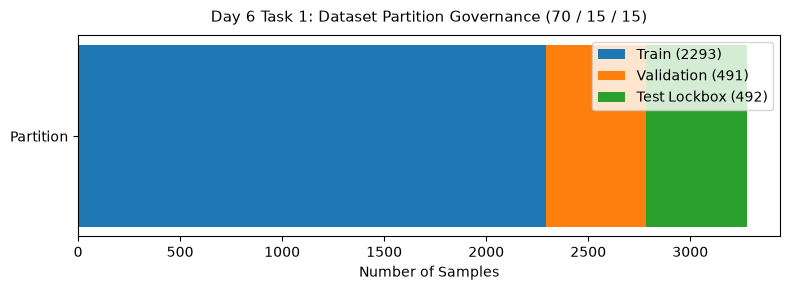

Saved partition allocation figure to: Day_Wise_Tasks\Day_6_Task_1\outputs\figures\day6_task1_partition_allocation.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(["Partition"], [n_train], color="#1f77b4", label=f"Train ({n_train})")
ax.barh(["Partition"], [n_val], left=[n_train], color="#ff7f0e", label=f"Validation ({n_val})")
ax.barh(["Partition"], [n_test], left=[n_train + n_val], color="#2ca02c", label=f"Test Lockbox ({n_test})")
ax.set_title("Day 6 Task 1: Dataset Partition Governance (70 / 15 / 15)", fontsize=11, pad=10)
ax.set_xlabel("Number of Samples")
ax.legend(loc="upper right")
plt.tight_layout()
fig_path = FIG_DIR / "day6_task1_partition_allocation.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved partition allocation figure to:", fig_path.relative_to(ROOT))

## 7. Governance Policy Table Serialization

Export data governance policies and partition specs to CSV.

In [8]:
tbl_path = TBL_DIR / "day6_task1_governance_policies.csv"
display(df_gov)
df_gov.to_csv(tbl_path, index=False)
print("Saved governance policies table to:", tbl_path.relative_to(ROOT))

,Rule_ID,Policy,Enforcement
0,GOV_01,Raw Data Immutability,Read-Only Permissions; SHA-256 Digest Verifica...
1,GOV_02,Chronological Partitioning,Strict Temporal Ordering (Train < Val < Test)
2,GOV_03,Test Lockbox Quarantine,Zero Access Until Final Unblinding
3,GOV_04,Deterministic Seed Control,Global Seed 42 Across All Stochastic Stages


Saved governance policies table to: Day_Wise_Tasks\Day_6_Task_1\outputs\tables\day6_task1_governance_policies.csv


## 8. Governance Gate Assertion

Assert that all governance policies are documented and enforceable.

In [9]:
assert len(policies) == 4
print("Day 6 Task 1 Quality Gate: PASSED.")

Day 6 Task 1 Quality Gate: PASSED.


# Day 6 - Assumptions and Methodology

## Assumptions

1. Test data remains strictly quarantined until all developmental modeling decisions are frozen.
2. Data governance rules apply universally to both raw and processed datasets.

## Day 6 Deliverable

Data governance charter, partition boundary chart, and serialized policy catalog.